# Capstone Part 2 — Dataset + Data Collection

## Early Prediction of Long-Running Administrative Cases
### Dataset Exploration using BPI Challenge 2015

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

The purpose of this notebook is to understand the dataset before building any predictive model. I first identify the
source and structure of the data, then inspect its quality and format, and finally perform a preliminary exploratory
analysis.

My project is about **administrative process data**. When an organisation handles an application (for example a
building permit), every step is recorded: the application is received, registered, reviewed, and a decision is sent.
Different cases can follow different paths through these steps, and some take much longer than others.

**Part 2 focuses only on understanding and preparing the dataset.** Predictive modelling comes in later Capstone stages.

## Project Question

> **Can early information from an administrative process eventually help us understand which cases are likely to take
> longer than usual?**

This notebook does **not** try to answer the prediction question yet. At Part 2, the goal is only to find out whether
the dataset contains relevant and usable process information for that later analysis.

## Specific Aim

To investigate whether information recorded early in an administrative process can later help identify cases that take
longer than usual.

**Planned later methods:** exploratory data analysis → defining a clear target → creating simple features → testing
classification or regression methods taught in the course.

**Assumptions and risks**

- Some fields are poorly documented, so their exact meaning is uncertain.
- Some optional fields contain a lot of missing data.
- The way the process works may change over time.
- The later prediction may or may not be successful.
- Any pattern found is an association, not proof of cause and effect.

## 1. Dataset Source and Access

| Item | Information |
|---|---|
| Dataset | **BPI Challenge 2015 — Municipality 1** |
| Creator | Boudewijn van Dongen (Eindhoven University of Technology) |
| Published | 2015, by Eindhoven University of Technology, on **4TU.ResearchData** |
| DOI (permanent link) | [10.4121/uuid:a0addfda-2044-4541-a450-fdcc9fe16d17](https://doi.org/10.4121/uuid:a0addfda-2044-4541-a450-fdcc9fe16d17) |
| Terms of use | **4TU General Terms of Use** ([doi.org/10.4121/resource:terms_of_use](https://doi.org/10.4121/resource:terms_of_use)), as listed in the dataset's DOI record |
| Content | Building-permit applications of one Dutch municipality, with activities labelled in Dutch and English |
| Geographic coverage | One municipality in the Netherlands (the municipality is not named in the data) |
| Time period | Events from October 2010 to July 2015 (calculated in Section 4) |
| Format | XES event log (an XML-based standard format for process data), file `BPIC15_1.xes` |

**How to access it:** open the DOI link above. It leads to the dataset page on 4TU.ResearchData, where the event log can
be downloaded for free. To run this notebook, save the file as `data/raw/BPIC15_1.xes` inside the project folder.
The file is not stored in the Git repository (it is large and not my own data); the DOI is the official way to get it.

**Why I am allowed to use it:** this is a **public research dataset** published for the Business Process Intelligence
(BPI) Challenge so that researchers and students can analyse it. It is:

- public and openly downloadable (not proprietary or confidential);
- not private personal data supplied to me by another organisation (people and resources appear only as anonymised
  numeric IDs);
- **not SPAR production data**. I use it as a public proof-of-concept dataset for a process like the ones SPAR handles.

## 2. What Is an Event Log?

An **event log** records the steps of a process. A simplified example for one case:

```
Case A:   Application received  →  Registration  →  Review  →  Decision sent
           (12 Mar)                 (12 Mar)          (20 Mar)    (2 May)
```

| Term | Meaning in this project |
|---|---|
| **Case** | one administrative application / process (here: one building-permit application) |
| **Event** | one recorded step within a case |
| **Activity** | what happened during that event (e.g. "send confirmation receipt") |
| **Timestamp** | when the event happened |
| **Resource** | the recorded person, team or system account linked to the event (anonymised ID) |

**One case usually contains many event rows**, one row per recorded step.

## 3. Loading and Formatting the Dataset

First I import the libraries and locate the data file. The path is found relative to the project folder, so the notebook
works on any computer where the project is downloaded.

In [1]:
import hashlib
import io
import os
import warnings
from contextlib import redirect_stderr, redirect_stdout
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# pm4py prints a long licence banner and a progress bar when it is used; hide them to keep the notebook readable.
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"
with redirect_stdout(io.StringIO()), redirect_stderr(io.StringIO()):
    import pm4py

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

# The project folder is the one that contains both "notebooks" and "data".
project_folder = Path.cwd()
if not (project_folder / "data").is_dir():
    project_folder = project_folder.parent
data_file = project_folder / "data" / "raw" / "BPIC15_1.xes"
print("Data file found:", data_file.relative_to(project_folder), "| exists:", data_file.exists())

Data file found: data\raw\BPIC15_1.xes | exists: True


Before loading, I record a **SHA-256 checksum** of the raw file. A checksum is a "fingerprint" of the file: if even one
byte changed, the fingerprint would be different. I check it again at the end of the notebook to prove that the raw
data was never modified.

In [2]:
def file_fingerprint(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

fingerprint_before = file_fingerprint(data_file)
print("SHA-256 of BPIC15_1.xes:", fingerprint_before)

SHA-256 of BPIC15_1.xes: 7591f70d4a4d536ead76a56c2fa493fbe22bf2ec7e06c8ddd29da79bd666e516


Now I load the XES file with **PM4Py** (a Python library for process data) and convert it into a **pandas DataFrame**.
This conversion is the most important *data munging* step in this notebook:

| | |
|---|---|
| **Source** | XES process-event log (nested XML: a log contains cases, a case contains events) |
| **Transformation** | PM4Py event log → pandas DataFrame (one flat table) |
| **Reason** | A DataFrame is much easier to inspect, summarise and visualise with pandas and matplotlib |

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # pm4py suggests an optional speed-up package; not needed here
    event_log = pm4py.read_xes(str(data_file), return_legacy_log_object=True)
    df = pm4py.convert_to_dataframe(event_log)

print("Rows:", len(df), "| Columns:", df.shape[1])
assert df.shape == (52217, 29), "STOP: the file does not have the expected 52,217 rows and 29 columns"
df.head()

Rows: 52217 | Columns: 29


,question,dateFinished,dueDate,action_code,activityNameEN,planned,time:timestamp,monitoringResource,org:resource,activityNameNL,concept:name,lifecycle:transition,case:endDate,case:caseStatus,case:SUMleges,case:last_phase,case:case_type,case:concept:name,case:Responsible_actor,case:parts,case:termName,case:endDatePlanned,case:startDate,case:requestComplete,case:IDofConceptCase,case:landRegisterID,case:caseProcedure,case:Includes_subCases,dateStop
0,EMPTY,2014-04-14 00:00:00,2014-04-17 07:30:39+00:00,01_HOOFD_010,register submission date request,2014-04-15 07:30:39+00:00,2014-04-10 22:00:00+00:00,2670601,9264148,registratie datum binnenkomst aanvraag,01_HOOFD_010,complete,2014-07-17 22:00:00+00:00,O,157.09305,Beschikking verzonden,557669,10009138,560464,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
1,False,2014-04-14 00:00:00,NaT,01_HOOFD_011,OLO messaging active,2014-04-15 07:34:03+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,OLO berichtenverkeer actief,01_HOOFD_011,complete,2014-07-17 22:00:00+00:00,O,157.09305,Beschikking verzonden,557669,10009138,560464,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
2,True,2014-04-14 00:00:00,NaT,01_HOOFD_020,send confirmation receipt,2014-04-15 07:34:03+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,versturen ontvangstbevestiging,01_HOOFD_020,complete,2014-07-17 22:00:00+00:00,O,157.09305,Beschikking verzonden,557669,10009138,560464,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
3,False,2014-04-14 00:00:00,2014-04-21 07:37:17+00:00,02_DRZ_010,forward to the competent authority,2014-04-15 07:37:17+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,doorsturen aan bevoegd gezag,02_DRZ_010,complete,2014-07-17 22:00:00+00:00,O,157.09305,Beschikking verzonden,557669,10009138,560464,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN
4,True,2014-04-14 00:00:00,NaT,04_BPT_005,regular procedure without MER,2014-04-15 07:37:22+00:00,2014-04-13 22:00:00+00:00,2670601,9264148,reguliere procedure zonder MER,04_BPT_005,complete,2014-07-17 22:00:00+00:00,O,157.09305,Beschikking verzonden,557669,10009138,560464,"Bouw,Reclame",Termijn bezwaar en beroep 1,2014-07-17 22:00:00+00:00,2014-04-10 22:00:00+00:00,TRUE,10009280,NaN,NaN,NaN,NaN


### What does one row represent?

> **One row in the DataFrame represents one recorded process event within an administrative case.**

- `case:concept:name` identifies the **case** the event belongs to.
- `concept:name` (the activity code), `activityNameEN` and `activityNameNL` describe **what happened**.
- `time:timestamp` records **when** the event happened.
- `org:resource` records the **resource** associated with the event.

The same case ID appears on many rows because one case contains many events. Columns that start with `case:` describe
the whole case, so their value is simply repeated on every row of that case.

In [4]:
first_case = df["case:concept:name"].iloc[0]
print("Number of rows (events) for case", first_case, ":", (df["case:concept:name"] == first_case).sum())
df.loc[df["case:concept:name"] == first_case, ["case:concept:name", "concept:name", "activityNameEN",
                                                "time:timestamp", "org:resource"]].head(6)

Number of rows (events) for case 10009138 : 45


,case:concept:name,concept:name,activityNameEN,time:timestamp,org:resource
0,10009138,01_HOOFD_010,register submission date request,2014-04-10 22:00:00+00:00,9264148
1,10009138,01_HOOFD_011,OLO messaging active,2014-04-13 22:00:00+00:00,9264148
2,10009138,01_HOOFD_020,send confirmation receipt,2014-04-13 22:00:00+00:00,9264148
3,10009138,02_DRZ_010,forward to the competent authority,2014-04-13 22:00:00+00:00,9264148
4,10009138,04_BPT_005,regular procedure without MER,2014-04-13 22:00:00+00:00,9264148
5,10009138,01_HOOFD_065_0,create procedure confirmation,2014-04-13 22:00:00+00:00,9264148


## 4. Dataset Overview

Every number below is calculated from the data, not typed in by hand.

In [5]:
overview = pd.Series({
    "Event rows": len(df),
    "Columns": df.shape[1],
    "Unique cases": df["case:concept:name"].nunique(),
    "Unique activity codes (concept:name)": df["concept:name"].nunique(),
    "Unique English activity names": df["activityNameEN"].nunique(),
    "Unique resources (org:resource)": df["org:resource"].nunique(),
    "Earliest event (UTC)": df["time:timestamp"].min(),
    "Latest event (UTC)": df["time:timestamp"].max(),
}, name="value")
overview.to_frame()

,value
Event rows,52217
Columns,29
Unique cases,1199
Unique activity codes (concept:name),398
Unique English activity names,289
Unique resources (org:resource),23
Earliest event (UTC),2010-10-04 22:00:00+00:00
Latest event (UTC),2015-07-31 22:00:00+00:00


In [6]:
events_per_case = df.groupby("case:concept:name").size()
events_per_case.describe()[["mean", "50%", "min", "max"]].rename({"50%": "median"}).round(1).to_frame("events per case")

,events per case
mean,43.6
median,44.0
min,2.0
max,101.0


**What these numbers mean:** the dataset contains about 52 thousand events spread over roughly 1,200 permit cases,
recorded between October 2010 and July 2015. A typical case has around 44 recorded steps, but some cases have only
2 and others more than 100. There are more activity codes (398) than English names (289) because several codes share the
same description. Only 23 resource IDs record all the work.

## 5. Data Dictionary

The table below describes **all 29 columns**. The *Meaning* column comes from the XES standard (for the standard
`concept:`, `time:`, `org:` and `lifecycle:` fields), from the dataset description, and from inspecting the values.
**Where the source does not document a field, I say so.** Any likely interpretation is marked **(inference)**.
The *Type / format* and *Missing %* columns are calculated directly from the DataFrame.

In [7]:
meanings = {
    "case:concept:name": ("Case ID: identifies the permit application the event belongs to.",
                          "Numeric ID stored as text; 1,199 cases."),
    "concept:name": ("Activity code of the event (XES standard activity name), e.g. 01_HOOFD_010.",
                     "398 codes. Main activity field used in this project."),
    "action_code": ("Activity code of the event.",
                    "Equal to concept:name on every row except one, where it is missing (see Section 8)."),
    "activityNameEN": ("English description of the activity.", "289 names; several codes share a name."),
    "activityNameNL": ("Dutch description of the activity.", "Same information as activityNameEN, in Dutch."),
    "time:timestamp": ("When the event happened (XES standard timestamp).",
                       "Stored in UTC. Many events are recorded at midnight, i.e. date-level precision."),
    "org:resource": ("Resource that recorded/performed the event (XES standard resource).",
                     "Anonymised numeric ID stored as text; 23 values. Not used to evaluate individuals."),
    "lifecycle:transition": ("Lifecycle state of the event (XES standard).", "Always 'complete' in this log."),
    "monitoringResource": ("A second resource ID per event. Exact source-system meaning is not fully documented; "
                           "possibly the resource monitoring the step (inference).", "Anonymised ID; 26 values."),
    "question": ("Exact source-system meaning is not fully documented; values look like answers recorded with "
                 "a step, e.g. True/False or a number (inference).",
                 "Missing answers are written as the text 'EMPTY' instead of a real missing value."),
    "planned": ("Exact meaning not fully documented; likely the planned date of the step (inference).",
                "Datetime (UTC)."),
    "dueDate": ("Exact meaning not fully documented; likely the deadline of the step (inference).",
                "Datetime (UTC); mostly missing."),
    "dateFinished": ("Exact meaning not fully documented; likely the date the step was finished (inference).",
                     "Stored as TEXT ('YYYY-MM-DD HH:MM:SS'), not as a datetime. Not converted here."),
    "dateStop": ("Exact source-system meaning is not fully documented.",
                 "Stored as text; only 2 rows have a value."),
    "case:startDate": ("Start date of the case.", "Datetime (UTC); case-level."),
    "case:endDate": ("End date of the case: the date the case was closed, when recorded.",
                     "Datetime (UTC); case-level. Missing for cases without a recorded end."),
    "case:endDatePlanned": ("Exact meaning not fully documented; likely a planned end date (inference).",
                            "Datetime (UTC); case-level; mostly missing."),
    "case:caseStatus": ("Status code of the case.", "Codes G / O / T; their meaning is not documented."),
    "case:requestComplete": ("Whether the application (request) was complete, judging by the name (inference).",
                             "Text 'TRUE' / 'FALSE', not a real boolean."),
    "case:last_phase": ("Last phase the case reached, as a Dutch label (e.g. 'Beschikking verzonden' ≈ 'decision sent').",
                        "27 values; describes the end of the case."),
    "case:case_type": ("Type of case.", "Only one value (557669) for every case."),
    "case:caseProcedure": ("Type of permit procedure: 'Regulier' ≈ regular, 'Uitgebreid' ≈ extended.",
                           "Case-level; mostly missing."),
    "case:parts": ("Permit components requested, comma-separated Dutch labels (e.g. 'Bouw' ≈ building).",
                   "Case-level; 88 different combinations."),
    "case:Responsible_actor": ("Exact meaning not fully documented; likely the responsible person/unit (inference).",
                               "Anonymised ID; 20 values."),
    "case:termName": ("Name of a legal time limit linked to the case (Dutch label, e.g. 'Termijn bezwaar en beroep').",
                      "Case-level; 13 values; often missing."),
    "case:SUMleges": ("Total fee of the application ('leges' is Dutch for fees) (inference from the name).",
                      "Number (float); case-level."),
    "case:Includes_subCases": ("Whether the case includes sub-cases: 'J' = ja (yes), 'N' = nee (no).",
                               "Case-level; often missing."),
    "case:IDofConceptCase": ("ID of a related 'concept' case. Exact meaning is not fully documented.",
                             "ID stored as text; often missing."),
    "case:landRegisterID": ("Land-register (cadastral) ID, judging by the name (inference).",
                            "ID stored as text; mostly missing."),
}

data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Meaning": [meanings[column][0] for column in df.columns],
    "Type / format": [str(df[column].dtype) for column in df.columns],
    "Missing %": (df.isna().mean() * 100).round(1).to_numpy(),
    "Unique values": [df[column].nunique() for column in df.columns],
    "Notes": [meanings[column][1] for column in df.columns],
})
assert len(data_dictionary) == 29 and set(meanings) == set(df.columns), "every column must be described"
data_dictionary

,Column,Meaning,Type / format,Missing %,Unique values,Notes
0,question,"Exact source-system meaning is not fully documented; values look like answers recorded with a step, e.g. True/False ...",str,0.0,422,Missing answers are written as the text 'EMPTY' instead of a real missing value.
1,dateFinished,Exact meaning not fully documented; likely the date the step was finished (inference).,str,0.0,5566,"Stored as TEXT ('YYYY-MM-DD HH:MM:SS'), not as a datetime. Not converted here."
2,dueDate,Exact meaning not fully documented; likely the deadline of the step (inference).,"datetime64[us, UTC]",93.6,3340,Datetime (UTC); mostly missing.
3,action_code,Activity code of the event.,str,0.0,397,"Equal to concept:name on every row except one, where it is missing (see Section 8)."
4,activityNameEN,English description of the activity.,str,0.0,289,289 names; several codes share a name.
5,planned,Exact meaning not fully documented; likely the planned date of the step (inference).,"datetime64[us, UTC]",11.5,38879,Datetime (UTC).
6,time:timestamp,When the event happened (XES standard timestamp).,"datetime64[us, UTC]",0.0,24142,"Stored in UTC. Many events are recorded at midnight, i.e. date-level precision."
7,monitoringResource,A second resource ID per event. Exact source-system meaning is not fully documented; possibly the resource monitorin...,str,0.0,26,Anonymised ID; 26 values.
8,org:resource,Resource that recorded/performed the event (XES standard resource).,str,0.0,23,Anonymised numeric ID stored as text; 23 values. Not used to evaluate individuals.
9,activityNameNL,Dutch description of the activity.,str,0.0,289,"Same information as activityNameEN, in Dutch."


In the *Type / format* column, `str` means text, `float64` means a decimal number and `datetime64[us, UTC]` means a
date and time stored in UTC (universal time).

I also save the dictionary as a separate file, `data/data_dictionary.csv`, so it can be submitted on its own.

In [8]:
data_dictionary.to_csv(project_folder / "data" / "data_dictionary.csv", index=False)
print("Saved data/data_dictionary.csv with", len(data_dictionary), "columns described")

Saved data/data_dictionary.csv with 29 columns described


### Key Columns for This Project

Not all 29 columns are equally important. These nine are the core of the analysis:

In [9]:
key_columns = ["case:concept:name", "concept:name", "activityNameEN", "time:timestamp", "org:resource",
               "case:startDate", "case:endDate", "case:requestComplete", "case:caseStatus"]
data_dictionary.set_index("Column").loc[key_columns, ["Meaning", "Type / format", "Missing %"]]

,Meaning,Type / format,Missing %
Column,,,
case:concept:name,Case ID: identifies the permit application the event belongs to.,str,0.0
concept:name,"Activity code of the event (XES standard activity name), e.g. 01_HOOFD_010.",str,0.0
activityNameEN,English description of the activity.,str,0.0
time:timestamp,When the event happened (XES standard timestamp).,"datetime64[us, UTC]",0.0
org:resource,Resource that recorded/performed the event (XES standard resource).,str,0.0
case:startDate,Start date of the case.,"datetime64[us, UTC]",0.0
case:endDate,"End date of the case: the date the case was closed, when recorded.","datetime64[us, UTC]",14.8
case:requestComplete,"Whether the application (request) was complete, judging by the name (inference).",str,0.0
case:caseStatus,Status code of the case.,str,0.0


- The **case ID, activity, timestamp and resource** are the four basic fields of any event log. Together they show
  which steps each case went through, in what order and when.
- **Start and end dates** show how long a case lasted, which is exactly what my project question is about.
- **requestComplete** and **caseStatus** describe the application itself and could matter later, once I have checked
  *when* their values become known.

## 6. Data Types and Formats

In [10]:
df.dtypes.value_counts().rename("number of columns").to_frame()

,number of columns
str,22
"datetime64[us, UTC]",6
float64,1


- **Date/time columns** (`time:timestamp`, `planned`, `dueDate`, `case:startDate`, `case:endDate`,
  `case:endDatePlanned`) were already converted to proper `datetime` values by PM4Py, so I can calculate with them
  directly (e.g. durations).
- **IDs and labels** (case IDs, activity codes, resources, status codes) are text. That is correct: an ID like
  `560912` is a label, not a quantity, so it should not be treated as a number.
- **Two date fields are stored as text** (`dateFinished`, `dateStop`), and `case:requestComplete` stores `TRUE`/`FALSE`
  as text. I checked below that the text dates can be read as dates, but I did **not** convert them, because I do not
  use them in this notebook. They can be converted later if an analysis needs them.

In [11]:
for column in ["dateFinished", "dateStop"]:
    values = df[column].dropna()
    readable = pd.to_datetime(values, errors="coerce").notna().sum()  # a test on a copy; df is not changed
    print(f"{column}: {len(values)} non-missing text values, {readable} can be read as dates")

dateFinished: 52217 non-missing text values, 52217 can be read as dates
dateStop: 2 non-missing text values, 2 can be read as dates


**Timestamps are stored in UTC.** In the Netherlands, midnight is 22:00 or 23:00 UTC, so a date-only event on
"12 March" appears as "11 March 23:00 UTC". When I count events or cases **per year** (Section 9.5), I therefore use
Dutch local time. This creates a separate helper variable and does not change the `df` table.

## 7. Data Munging

*Munging* means changing the **structure or format** of the data so it can be analysed. (Cleaning, in the next
section, means checking and fixing **quality problems**.)

| Step | What I did | Why |
|---|---|---|
| 1 | Started from the original **XES event log** (nested XML) | This is the official published format |
| 2 | **Loaded it with PM4Py** | PM4Py understands the XES structure (log → cases → events) |
| 3 | **Converted it to one pandas DataFrame** | A flat table is easy to inspect, count and plot |
| 4 | Event attributes and case attributes became **DataFrame columns**; case attributes get the prefix `case:` and are repeated on each event row of the case | Every row has all the information it needs |
| 5 | **Inspected the data types**: the six date/time fields are already `datetime` (UTC); two text date fields were checked but left unchanged | Dates must be real dates to calculate durations |
| 6 | Built **summary tables per case** for the EDA (events per case, case duration, activity sequence) | The questions in Section 9 are about cases, not single events |
| 7 | Used **Dutch local time** only as a helper for counting per year | So that dates fall in the correct calendar year |

The XES → DataFrame conversion is **formatting, not cleaning**: no value was corrected, added or removed.

## 8. Data Cleaning and Quality Checks

Before exploring the data, I check its quality: missing values, duplicates, consistency and formats.

### A. Missing values

In [12]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1),
})
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)
print(f"{len(missing)} of {df.shape[1]} columns have missing values:")
missing

14 of 29 columns have missing values:


,missing_count,missing_percent
dateStop,52215,100.0
dueDate,48877,93.6
case:caseProcedure,46538,89.1
case:endDatePlanned,45090,86.4
case:landRegisterID,44210,84.7
case:IDofConceptCase,16381,31.4
case:termName,13743,26.3
case:Includes_subCases,11280,21.6
case:SUMleges,8632,16.5
case:endDate,7744,14.8


In [13]:
key_fields = ["case:concept:name", "concept:name", "time:timestamp", "org:resource"]
df[key_fields].isna().sum().rename("missing values").to_frame()

,missing values
case:concept:name,0
concept:name,0
time:timestamp,0
org:resource,0


**Result:** 14 of 29 columns have missing values. A few optional fields are almost completely empty, such as
`dateStop`, `dueDate`, `case:caseProcedure`, `case:endDatePlanned` and `case:landRegisterID`.

**The four key process fields (case ID, activity, timestamp and resource) have no missing values.** This is the most
important result: the core event log is complete.

**Decision:** I do **not** delete or fill in (impute) the sparse columns now. A column that is mostly empty is not
automatically useless; its gaps can also carry meaning. For example, a missing `case:endDate` means the case had no
recorded closing date. Columns can be dropped later if an analysis gives a clear reason.

One more check: the column `question` has *no* missing values according to pandas, but it uses the **text "EMPTY"**
as a placeholder. This is a hidden kind of missing value:

In [14]:
print("Rows where question == 'EMPTY':", (df["question"] == "EMPTY").sum(),
      f"({(df['question'] == 'EMPTY').mean():.1%} of rows)")

Rows where question == 'EMPTY': 28546 (54.7% of rows)


I note this and leave the values unchanged, because `question` is not used in this notebook.

### B. Duplicate rows

In [15]:
duplicate_rows = df.duplicated().sum()
print("Fully duplicated event rows:", duplicate_rows)

Fully duplicated event rows: 0


**No fully duplicated event rows were found, so no duplicate rows were removed.**

### C. Basic consistency

Do the key fields exist, and do related values agree with each other?

In [16]:
checks = pd.Series({
    "every row has a case ID": df["case:concept:name"].notna().all(),
    "every row has an activity code": df["concept:name"].notna().all(),
    "every row has a timestamp": df["time:timestamp"].notna().all(),
    "every row has a resource": df["org:resource"].notna().all(),
    "case attributes are identical on all rows of a case": all(
        df.groupby("case:concept:name")[column].nunique(dropna=False).max() == 1
        for column in df.columns if column.startswith("case:")),
    "action_code equals concept:name on every row": (df["action_code"] == df["concept:name"]).all(),
}, name="check passed")
checks.to_frame()

,check passed
every row has a case ID,True
every row has an activity code,True
every row has a timestamp,True
every row has a resource,True
case attributes are identical on all rows of a case,True
action_code equals concept:name on every row,False


All checks pass except the last one. Let's look at the row where `action_code` differs:

In [17]:
df.loc[df["action_code"].isna(), ["case:concept:name", "concept:name", "action_code", "activityNameEN"]]

,case:concept:name,concept:name,action_code,activityNameEN
26037,4565008,99_NOCODE_04,NaN,send letter receptive test not ok wait for report firedepartement


Exactly **one** row has no `action_code`. Its activity code in `concept:name` is `99_NOCODE_04`, so the source system
apparently had no action code for this step. I **do not repair it**: `concept:name` is complete and is the activity
field I use, so this single gap does not affect the analysis.

Some other values are worth knowing about:

In [18]:
case_table = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    start_date=("case:startDate", "first"),
)
local_time = df["time:timestamp"].dt.tz_convert("Europe/Amsterdam")
at_midnight = (local_time.dt.hour == 0) & (local_time.dt.minute == 0) & (local_time.dt.second == 0)

print("Values of lifecycle:transition:", df["lifecycle:transition"].unique().tolist())
print("Values of case:case_type:", df["case:case_type"].unique().tolist())
print("Cases where case:startDate equals the first event:", (case_table["start_date"] == case_table["first_event"]).sum(),
      "of", len(case_table))
print(f"Events recorded at exactly midnight (local time): {at_midnight.mean():.0%}")

Values of lifecycle:transition: ['complete']
Values of case:case_type: ['557669']
Cases where case:startDate equals the first event: 1178 of 1199
Events recorded at exactly midnight (local time): 46%


- `lifecycle:transition` and `case:case_type` each have **only one value**, so they carry no information that could
  separate cases.
- `case:startDate` matches the first recorded event for most cases, but not all. A small number of cases have their
  first event on a different date than the recorded start date. In this notebook, durations use the event timestamps
  (Section 9.1), and the difference is documented rather than "fixed".
- Almost half of all events are recorded at exactly midnight. This means many timestamps contain only a **date**, not
  a precise time. Durations in days are fine, but the order of events on the same day is uncertain.

### D. What was actually changed?

The table separates what I **checked** from what I **changed**:

| Action | Result / decision |
|---|---|
| Converted XES to DataFrame | **Yes** (formatting / munging) |
| Converted/verified timestamps | **Verified:** PM4Py already loads the six date fields as UTC datetimes. Text dates (`dateFinished`, `dateStop`) checked, **not converted**. Local time used only as a helper for per-year counts |
| Removed duplicate rows | **No:** none found |
| Dropped rows with missing values | **No** |
| Imputed (filled in) missing values | **No** |
| Removed sparse optional columns | **No:** kept and documented |
| Repaired the one missing `action_code` | **No:** documented; `concept:name` is complete |
| Replaced the text "EMPTY" in `question` | **No:** documented |
| Modified the raw XES file | **No:** checksum verified at the end |

**All 52,217 rows and 29 columns are kept.**

## 9. Preliminary Exploratory Data Analysis

Five simple questions about the cases. To answer them I build small per-case summaries from the event table.

### 9.1 How Long Do Cases Last?

**Definition used:** duration = time between the **first** and the **last** recorded event of a case, in days.

I only use cases that have a recorded end date (`case:endDate` present). For cases without one, the process may have
continued after the data was collected, so their duration would be incomplete.

In [19]:
per_case = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
per_case["duration_days"] = (per_case["last_event"] - per_case["first_event"]).dt.total_seconds() / (24 * 60 * 60)
closed = per_case[per_case["end_date"].notna()]

print("Cases with a recorded end date:", len(closed), "of", len(per_case))
closed["duration_days"].describe().round(1).to_frame()

Cases with a recorded end date: 956 of 1199


,duration_days
count,956.0
mean,98.1
std,117.4
min,1.4
25%,47.4
50%,63.0
75%,102.5
max,1486.0


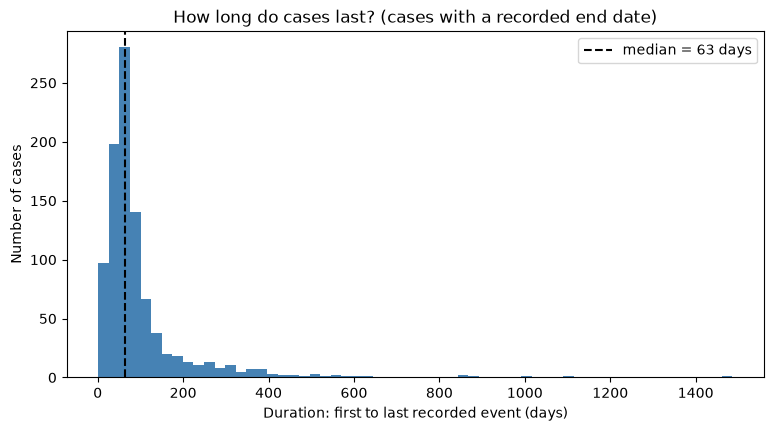

Skewness of duration: 4.8


In [20]:
plt.figure(figsize=(9, 4.5))
plt.hist(closed["duration_days"], bins=60, color="steelblue")
plt.axvline(closed["duration_days"].median(), color="black", linestyle="--",
            label=f"median = {closed['duration_days'].median():.0f} days")
plt.title("How long do cases last? (cases with a recorded end date)")
plt.xlabel("Duration: first to last recorded event (days)")
plt.ylabel("Number of cases")
plt.legend()
plt.show()
print("Skewness of duration:", round(closed["duration_days"].skew(), 1))

**What it means:** most cases finish within roughly two to three months (median about 63 days, half of the cases between
about 47 and 103 days). The distribution is strongly **right-skewed** (skewness ≈ 4.8): a long tail of cases runs for
many months or even years, up to about four years. Because of this tail the mean (≈ 98 days) is much higher than the
median. These long cases are simply longer than typical; this does not mean they were legally late or overdue.

### 9.2 How Many Events Does a Case Contain?

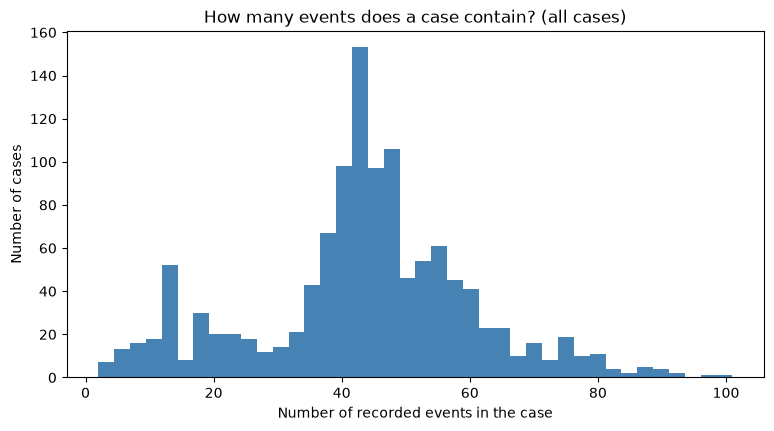

mean 43.6 | median 44 | min 2 | max 101


In [21]:
plt.figure(figsize=(9, 4.5))
plt.hist(events_per_case, bins=40, color="steelblue")
plt.title("How many events does a case contain? (all cases)")
plt.xlabel("Number of recorded events in the case")
plt.ylabel("Number of cases")
plt.show()
print(f"mean {events_per_case.mean():.1f} | median {events_per_case.median():.0f} | "
      f"min {events_per_case.min()} | max {events_per_case.max()}")

**What it means:** a typical case has about 44 recorded steps. About 70% of cases have between 30 and 60, while about
one case in ten has fewer than 20 and the most complex ones have around 100. Cases differ not only in **how long** they
take but also in **how many steps** are recorded.

### 9.3 What Activities Occur Most Often?

I use the English activity names because they are readable.

In [22]:
top_activities = df["activityNameEN"].value_counts().head(10)
top_activities.rename_axis("activity").rename("count").to_frame()

,count
activity,
send confirmation receipt,2074
procedure change,1752
enter senddate decision environmental permit,1397
request complete,1267
register submission date request,1199
phase application received,1199
forward to the competent authority,1179
regular procedure without MER,1161
enter senddate acknowledgement,1057


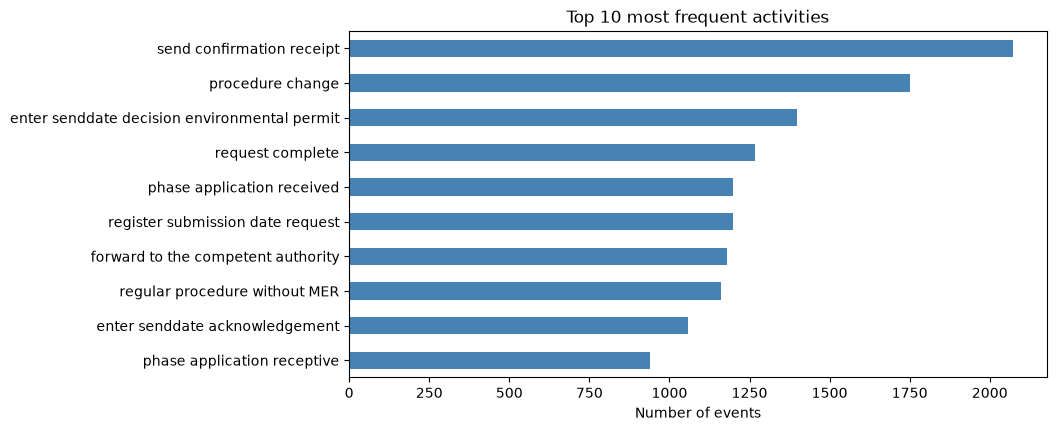

In [23]:
plt.figure(figsize=(9, 4.5))
top_activities.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 most frequent activities")
plt.xlabel("Number of events")
plt.ylabel("")
plt.show()

**What it means:** some steps happen in almost every case. For example "register submission date request" and "phase
application received" occur exactly once per case (1,199 times), while others, like "send confirmation receipt", can
happen more than once in the same case. Many of the 398 activity codes are much rarer and appear only in some cases.

### 9.4 Do All Cases Follow the Same Path?

A **process variant** is the exact sequence of activity codes in a case, from first to last. If two cases performed the
same steps in the same order, they share a variant.

In [24]:
sequences = df.groupby("case:concept:name", sort=False)["concept:name"].agg(tuple)
variant_counts = sequences.value_counts()

print("Cases:", len(sequences))
print("Unique activity sequences (variants):", len(variant_counts))
print("Variants that occur only once:", (variant_counts == 1).sum())

Cases: 1199
Unique activity sequences (variants): 1170
Variants that occur only once: 1155


**What it means:** there are about as many different sequences as cases. **Almost every case follows its own slightly
different path** through the process, so the process is highly variable. (Part of this comes from the date-only
timestamps: steps on the same day may be stored in an arbitrary order.)

### 9.5 How Is the Dataset Distributed Over Time?

I count how many cases **started** in each year (year of the first event, in Dutch local time).

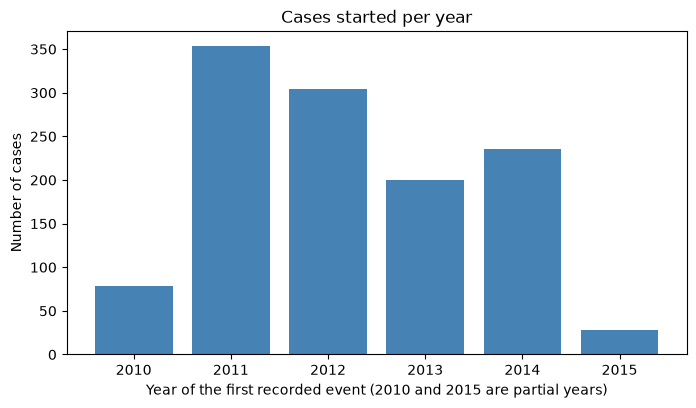

year,2010,2011,2012,2013,2014,2015
cases started,79,353,304,200,235,28


In [25]:
start_year = per_case["first_event"].dt.tz_convert("Europe/Amsterdam").dt.year
cases_per_year = start_year.value_counts().sort_index().rename_axis("year")

plt.figure(figsize=(8, 4.2))
plt.bar(cases_per_year.index.astype(str), cases_per_year.to_numpy(), color="steelblue")
plt.title("Cases started per year")
plt.xlabel("Year of the first recorded event (2010 and 2015 are partial years)")
plt.ylabel("Number of cases")
plt.show()
cases_per_year.rename("cases started").to_frame().T

**What it means:** most cases started between 2011 and 2014. **2010 and 2015 are partial years**: the log begins in
October 2010 and ends in July 2015. The low numbers in those years come from incomplete coverage and should **not**
be read as a real drop in activity.

### 9.6 Resources (brief)

In [26]:
print("Unique resources:", df["org:resource"].nunique())
print("Median number of different resources per case:",
      int(df.groupby("case:concept:name")["org:resource"].nunique().median()))

Unique resources: 23
Median number of different resources per case: 3


The log contains 23 anonymised resource IDs, and a typical case involves only a few of them.

> **Resource information is used only to understand process structure. This project does not evaluate or rank
> individuals.**

## 10. Preliminary Findings

1. The dataset contains **1,199 cases and 52,217 process events** (Oct 2010 – Jul 2015).
2. Cases vary considerably in **duration** (median about 63 days, right-skewed, some lasting years) and in the
   **number of recorded events** (2 to 101, typically around 44).
3. The process is **highly variable**: 1,170 unique activity sequences across 1,199 cases.
4. Some administrative activities occur **much more frequently** than others; a core set appears in almost every case.
5. The **core event-log fields** (case, activity, timestamp, resource) are complete, with no duplicate rows. Missing
   values are concentrated in optional fields.

The preliminary EDA suggests that the dataset contains meaningful process variation and is suitable for further
investigation. At this stage, no predictive conclusion is being made.

## 11. Does This Dataset Fit the Project Question?

**Yes. The dataset is relevant to the project question.** It contains:

- **case identifiers**, so events can be grouped into cases;
- **event sequences**, which show what happened in each case and in what order;
- **timestamps**, which show when each step happened and how long cases took;
- **activities** and **resources**, which describe the steps and who recorded them;
- **start and end information** for most cases;
- enough time and process information to study how cases develop from their first days onwards.

However, we do **not** yet know whether the *early* events of a case contain enough information to predict which cases
will take longer. That will be tested in later Capstone stages.

**Conclusion:** the dataset is suitable for continuing the project, but its predictive usefulness still needs to be
evaluated in later Capstone stages.

## 12. Dataset Limitations

- Data from **one Dutch municipality** only.
- A **historical period** (2010–2015); procedures may have changed since.
- **2010 and 2015 are partial years.**
- Some optional fields have **high missingness**.
- Some field meanings are **not fully documented** (e.g. `question`, case status codes).
- **Limited timestamp precision**: many events have a date but no exact time.
- This is **external data**, not Montenegro/SPAR production data.
- Results may **not generalise** to other organisations or processes.

## 13. Next Steps

In the next Capstone stages I plan to:

1. choose a clear outcome/target (for example, what counts as "taking longer than usual");
2. create simple features from information available early in each case;
3. test classification or regression techniques taught in class;
4. evaluate honestly whether early process information contains a useful predictive signal.

## 14. Five-Minute Presentation Guide

**0:00–0:45: Project idea and question**
- "My project looks at administrative processes, like handling a permit application. Some cases are finished in a few
  weeks, others take many months."
- "My question is: can early information about a case eventually help us see which cases will take longer than usual?
  In Part 2 I'm not predicting anything yet; I'm checking whether the data can support that question."

**0:45–1:30: Dataset source and what an event log is**
- "I'm using a public research dataset, the BPI Challenge 2015, Municipality 1. It's published with a DOI on
  4TU.ResearchData, so anyone can download it. It's not SPAR data and contains no confidential information."
- "It's an event log: every row is one step in one case, with what happened, when, and which anonymised resource
  recorded it."

**1:30–2:15: Data structure, munging and cleaning**
- "The file comes as XES, a process-data format. I loaded it with PM4Py and turned it into a pandas DataFrame:
  52,217 rows and 29 columns, and I wrote a data dictionary for every column."
- "For quality, I checked missing values, duplicates and consistency. The key fields are complete and there are no
  duplicates. Some optional fields are mostly empty, but I kept them and documented them. I didn't delete or fill in
  anything."

**2:15–4:15: Strongest EDA findings**
- "Case duration is very skewed: the median case takes about two months, but some take years."
- "A typical case has about 44 recorded steps, but it ranges from 2 to about 100."
- "The most surprising finding: there are 1,170 different step sequences among 1,199 cases, so almost every case
  takes its own path."
- "Most cases started between 2011 and 2014. 2010 and 2015 look low only because the data covers part of those years."

**4:15–5:00: Suitability, limitations and next steps**
- "The dataset has everything my question needs: cases, steps, timestamps and start/end dates. So it's suitable to
  continue."
- "Limitations: it's one Dutch municipality, from 2010–2015, and some fields aren't well documented."
- "Next, I'll define a clear target, build simple early features, and test the models from class."

## Part 2 Submission Checklist

- [x] Public dataset documented
- [x] Official source/access information provided
- [x] Time period and geographic context documented
- [x] One row explained
- [x] Complete 29-column data dictionary included
- [x] Data types/formats inspected
- [x] Data munging documented
- [x] Missing values inspected
- [x] Duplicate rows checked
- [x] Cleaning decisions documented
- [x] Preliminary EDA completed
- [x] Dataset suitability discussed
- [x] Dataset limitations discussed
- [x] Next steps stated
- [x] No predictive model built in Part 2 notebook

Final check: the raw data file must have exactly the same fingerprint as at the start.

In [27]:
fingerprint_after = file_fingerprint(data_file)
print("SHA-256 before:", fingerprint_before)
print("SHA-256 after: ", fingerprint_after)
print("Raw file unchanged:", fingerprint_before == fingerprint_after)
print("Rows still in the DataFrame:", len(df), "| columns:", df.shape[1])

SHA-256 before: 7591f70d4a4d536ead76a56c2fa493fbe22bf2ec7e06c8ddd29da79bd666e516
SHA-256 after:  7591f70d4a4d536ead76a56c2fa493fbe22bf2ec7e06c8ddd29da79bd666e516
Raw file unchanged: True
Rows still in the DataFrame: 52217 | columns: 29
